<a href="https://colab.research.google.com/github/devang-bais/heart-disease-analysis/blob/main/heart_eda_colab_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Dataset — Exploratory Data Analysis (EDA)

This notebook is adapted from the uploaded `Heart.ipynb` and prepared to run in Google Colab. Upload `heart.csv` when prompted. The analysis is for learning and is not medical advice.

## 1. Upload the dataset
Run this cell first in a fresh Colab session.

In [3]:
from google.colab import files
uploaded = files.upload()

# The uploaded file should be named heart.csv. If its name differs, update the filename below.


Saving heart (1).csv to heart (1) (1).csv


## 2. Import libraries and load data

In [5]:
from google.colab import files
import pandas as pd
import io

# Upload dataset
uploaded = files.upload()

# Automatically detect uploaded filename
filename = list(uploaded.keys())[0]

# Read dataset
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("File loaded successfully:", filename)
print("Dataset shape:", df.shape)

display(df.head())

Saving heart (1).csv to heart (1) (2).csv
File loaded successfully: heart (1) (2).csv
Dataset shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Basic inspection

In [11]:
print('Columns:')
print(df.columns.tolist())
print('\nShape:', df.shape)
print('\nData types and non-null counts:')
df.info()


Columns:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Shape: (918, 12)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage

In [12]:
display(df.describe(include='all').T)
print('Duplicate rows:', df.duplicated().sum())
print('\nMissing values per column:')
display(df.isnull().sum().to_frame('missing_values'))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,918.0,NaN,NaN,NaN,132.396514,18.514154,0.0,120.0,130.0,140.0,200.0
Cholesterol,918.0,NaN,NaN,NaN,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,918.0,NaN,NaN,NaN,136.809368,25.460334,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2


Duplicate rows: 0

Missing values per column:


,missing_values
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


## 4. Target distribution

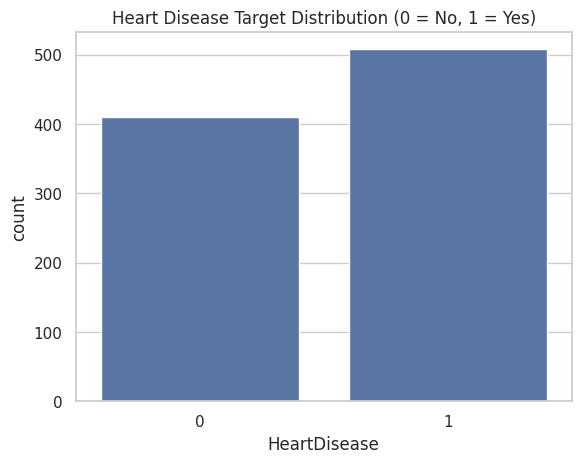

,count
HeartDisease,
0,410
1,508


In [13]:
ax = sns.countplot(data=df, x='HeartDisease')
ax.set_title('Heart Disease Target Distribution (0 = No, 1 = Yes)')
ax.set_xlabel('HeartDisease')
plt.show()
display(df['HeartDisease'].value_counts().sort_index().to_frame('count'))

## 5. Numeric feature distributions

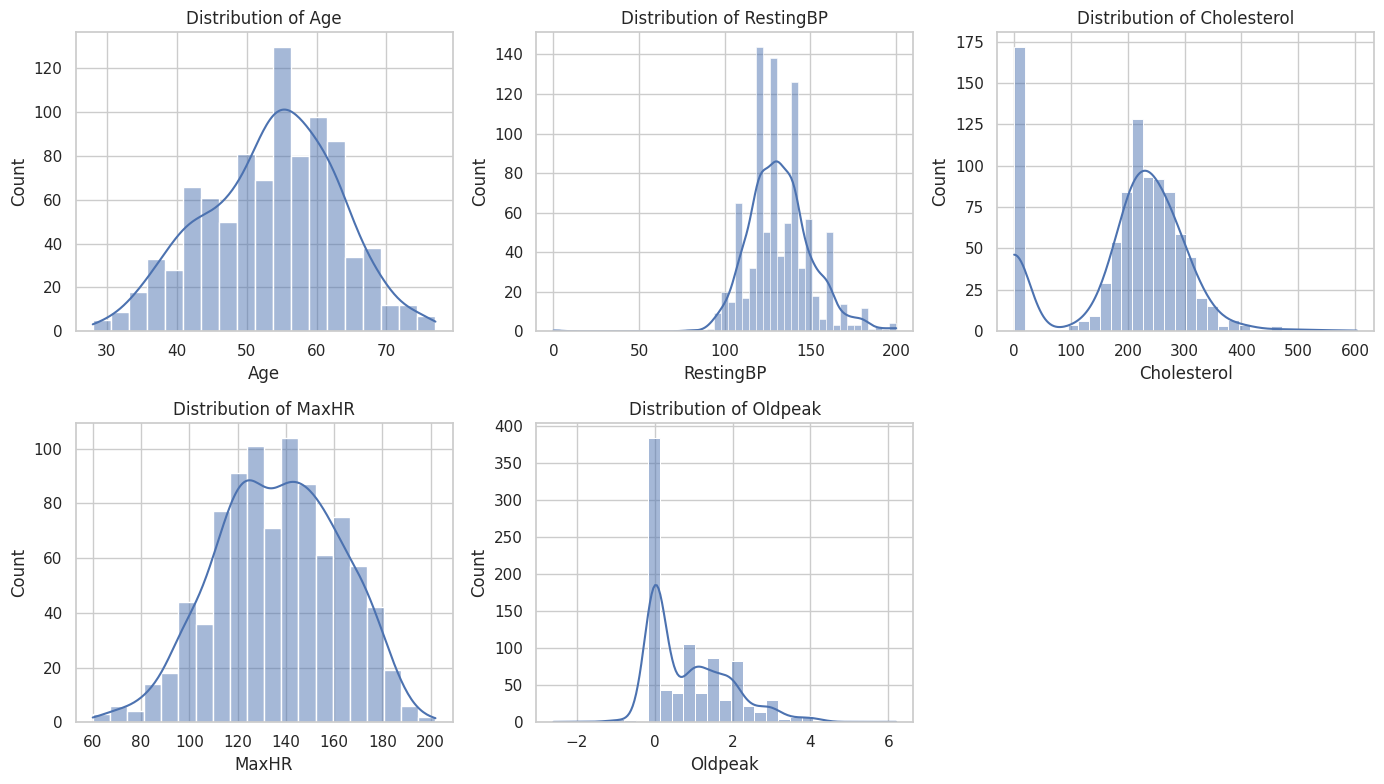

In [14]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(numeric_cols, axes.flat):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

## 6. Check unusual zero values
In this dataset, zero cholesterol values may be placeholders. Review them before deciding how to handle them. RestingBP equal to zero is also checked.

In [15]:
for col in ['Cholesterol', 'RestingBP']:
    print(f'{col} values equal to 0:', (df[col] == 0).sum())

Cholesterol values equal to 0: 172
RestingBP values equal to 0: 1


## 7. Categorical features vs heart disease

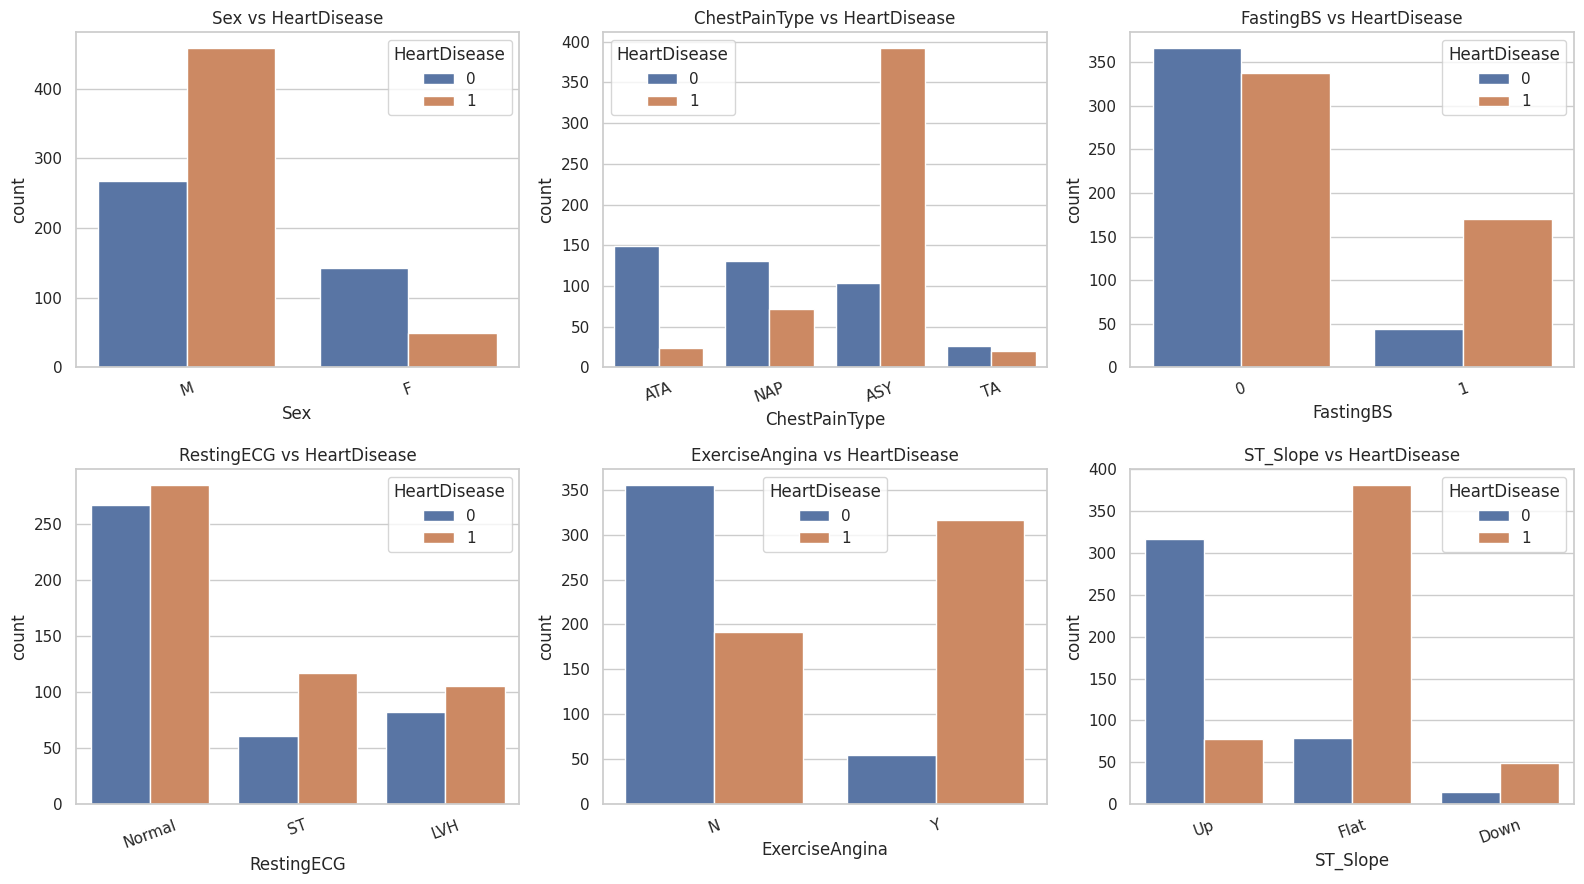

In [16]:
categorical_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, ax in zip(categorical_cols, axes.flat):
    sns.countplot(data=df, x=col, hue='HeartDisease', ax=ax)
    ax.set_title(f'{col} vs HeartDisease')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## 8. Compare numeric features by target

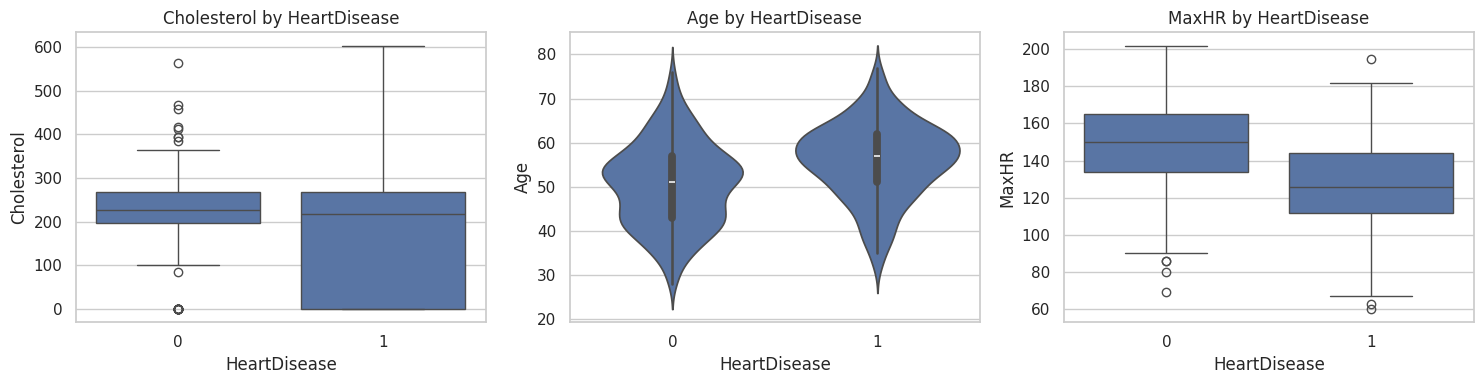

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x='HeartDisease', y='Cholesterol', ax=axes[0])
axes[0].set_title('Cholesterol by HeartDisease')
sns.violinplot(data=df, x='HeartDisease', y='Age', ax=axes[1])
axes[1].set_title('Age by HeartDisease')
sns.boxplot(data=df, x='HeartDisease', y='MaxHR', ax=axes[2])
axes[2].set_title('MaxHR by HeartDisease')
plt.tight_layout()
plt.show()

## 9. Correlation heatmap

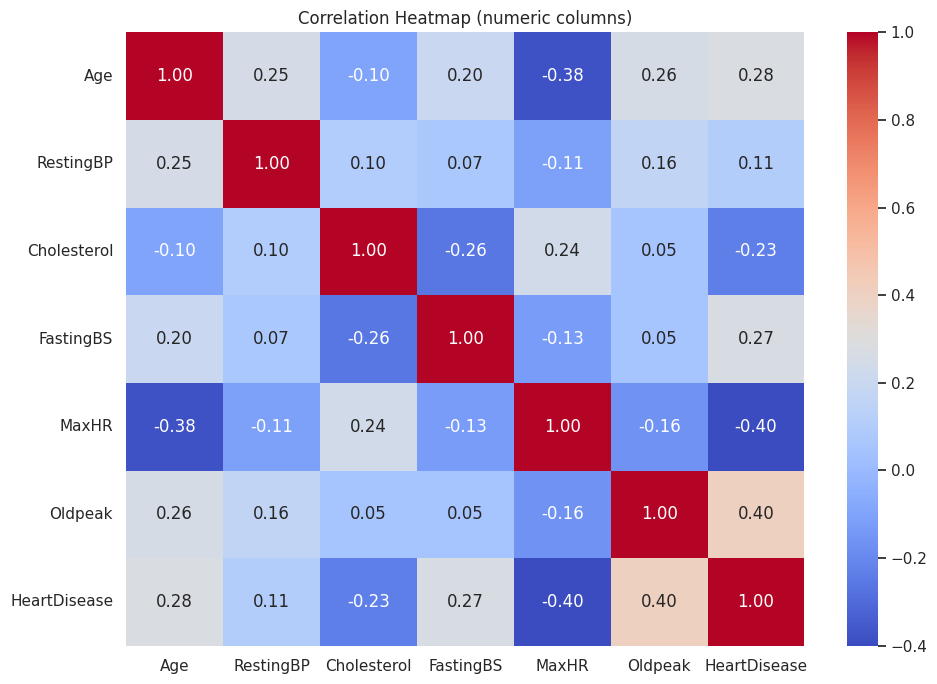

In [18]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap (numeric columns)')
plt.tight_layout()
plt.show()

## 10. Data preprocessing and encoding
This creates a separate cleaned/encoded copy. It replaces zero values in Cholesterol and RestingBP with the mean of non-zero values as in the original notebook. Review whether this treatment is appropriate for your analysis before using it in a model.

In [19]:
df_cleaned = df.copy()
for col in ['Cholesterol', 'RestingBP']:
    nonzero_mean = df_cleaned.loc[df_cleaned[col] != 0, col].mean()
    df_cleaned[col] = df_cleaned[col].replace(0, nonzero_mean)

# One-hot encode categorical columns; keep the original df unchanged.
df_encode = pd.get_dummies(df_cleaned, drop_first=True, dtype=int)
display(df_encode.head())
print('Encoded dataset shape:', df_encode.shape)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,1,1,0,0,1,0,0,0,1
1,49,160.0,180.0,0,156,1.0,1,0,0,1,0,1,0,0,1,0
2,37,130.0,283.0,0,98,0.0,0,1,1,0,0,0,1,0,0,1
3,48,138.0,214.0,0,108,1.5,1,0,0,0,0,1,0,1,1,0
4,54,150.0,195.0,0,122,0.0,0,1,0,1,0,1,0,0,0,1


Encoded dataset shape: (918, 16)


## 11. Standardize numeric features (optional)
Use this step when preparing data for a model that benefits from scaling. The target column is not scaled.

In [ ]:
from sklearn.preprocessing import StandardScaler
numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
df_scaled = df_encode.copy()
df_scaled[numerical_cols] = scaler.fit_transform(df_scaled[numerical_cols])
display(df_scaled.head())

## Summary
Use the charts and tables above to describe target balance, feature distributions, categorical associations, possible unusual values, and correlations. Do not interpret these exploratory associations as proof of causation or as a medical diagnosis.